Text(0.5, 1.0, 'Correlation Heatmap')

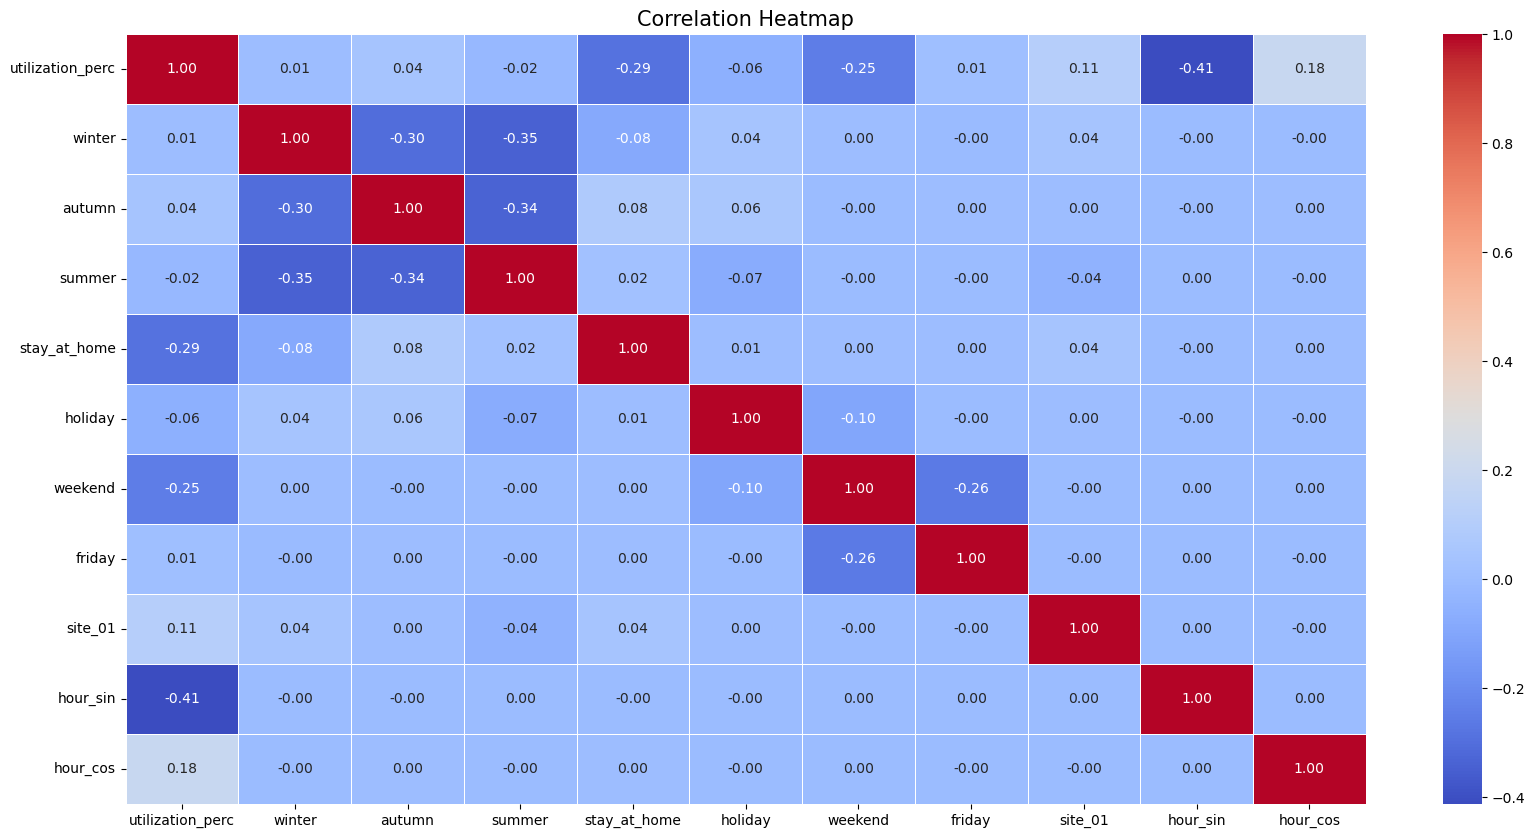

In [124]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = utilization[['utilization_perc', 'winter', 'autumn', 'summer', 'stay_at_home',
       'holiday', 'weekend', 'friday', 'site_01', 'hour_sin', 'hour_cos']].corr()

# Set up the matplotlib figure
plt.figure(figsize=(20, 10))

# Create a heatmap with the correlation matrix, including correlation coefficients
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, cbar=True)

# Set the title for the heatmap
plt.title('Correlation Heatmap', size=15)

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input, Dropout
import pandas as pd
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import RMSprop, Adam
from keras_tuner.tuners import RandomSearch

In [39]:
# Import the Data
utilization = pd.read_csv('utilization_final.csv')

In [40]:
utilization['timestamp'] = pd.to_datetime(utilization['timestamp'])
cutoff_time = pd.to_datetime('2020-03-18 23:59:59')
duplicate_rows = utilization[utilization['timestamp'] < cutoff_time].index

# Drop these rows
utilization.drop(duplicate_rows,inplace=True)

In [41]:
utilization

,timestamp,utilization_absolute,utilization_perc,temperature,precipitation,winter,autumn,summer,stay_at_home,holiday,...,hour_sin,hour_cos,weekday,month,weekday_sin,weekday_cos,month_sin,month_cos,in_gap,day_of_week
29233,2020-03-19 00:00:00,0.00,0.00,15.0,0.0,0,0,0,1,0,...,0.000000,1.000000e+00,3,3,0.433884,-0.900969,1.0,6.123234e-17,False,3
29234,2020-03-19 00:00:00,1.00,0.02,15.0,0.0,0,0,0,1,0,...,0.000000,1.000000e+00,3,3,0.433884,-0.900969,1.0,6.123234e-17,False,3
29235,2020-03-19 01:00:00,1.00,0.02,15.0,0.0,0,0,0,1,0,...,0.258819,9.659258e-01,3,3,0.433884,-0.900969,1.0,6.123234e-17,False,3
29236,2020-03-19 01:00:00,0.00,0.00,15.0,0.0,0,0,0,1,0,...,0.258819,9.659258e-01,3,3,0.433884,-0.900969,1.0,6.123234e-17,False,3
29237,2020-03-19 02:00:00,0.00,0.00,14.0,0.0,0,0,0,1,0,...,0.500000,8.660254e-01,3,3,0.433884,-0.900969,1.0,6.123234e-17,False,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55236,2021-09-14 04:00:00,1.00,0.02,17.1,0.0,0,1,0,0,0,...,0.866025,5.000000e-01,1,9,0.781831,0.623490,-1.0,-1.836970e-16,False,1
55237,2021-09-14 05:00:00,1.00,0.02,16.2,0.0,0,1,0,0,0,...,0.965926,2.588190e-01,1,9,0.781831,0.623490,-1.0,-1.836970e-16,False,1
55238,2021-09-14 06:00:00,1.00,0.02,16.1,0.0,0,1,0,0,0,...,1.000000,6.123234e-17,1,9,0.781831,0.623490,-1.0,-1.836970e-16,False,1
55239,2021-09-14 07:00:00,0.77,0.01,15.0,0.0,0,1,0,0,0,...,0.965926,-2.588190e-01,1,9,0.781831,0.623490,-1.0,-1.836970e-16,False,1


In [42]:
utilization.columns

Index(['timestamp', 'utilization_absolute', 'utilization_perc', 'temperature',
       'precipitation', 'winter', 'autumn', 'summer', 'stay_at_home',
       'holiday', 'weekend', 'friday', 'hour', 'site_01', 'hour_sin',
       'hour_cos', 'weekday', 'month', 'weekday_sin', 'weekday_cos',
       'month_sin', 'month_cos', 'in_gap', 'day_of_week'],
      dtype='object')

In [43]:
# Drop the columns we don't need for the model from here
#utilization.drop(['hour','timestamp','utilization_absolute','temperature','precipitation'],axis=1,inplace=True)
utilization.drop(['timestamp', 'utilization_absolute', 
       'precipitation', 
       'holiday',
        'hour', 'month_sin', 'in_gap','temperature',
       'month_cos','winter','autumn','summer','weekend','friday'],axis=1,inplace=True)

In [44]:
# Scale the features to (0, 1)
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(utilization)

# Convert to a DataFrame
scaled_data = pd.DataFrame(scaled_data, columns=utilization.columns)

In [45]:
utilization.columns

Index(['utilization_perc', 'stay_at_home', 'site_01', 'hour_sin', 'hour_cos',
       'weekday', 'month', 'weekday_sin', 'weekday_cos', 'day_of_week'],
      dtype='object')

In [46]:
# Create sequences from the data
def create_sequences(data, sequence_length, target_column):
    X, y = [], []
    target_index = data.columns.get_loc(target_column)  # Get the index of the target column
    for i in range(len(data) - sequence_length):
        # Use all columns except the target column for X
        X.append(data.iloc[i:i+sequence_length].drop(columns=[target_column]).values)
        # Use only the target column for y
        y.append(data.iloc[i+sequence_length][target_column])
    return np.array(X), np.array(y)

# Define sequence length 
sequence_length = 24
target_column = "utilization_perc"
X, y = create_sequences(utilization, sequence_length, target_column)

# Check shapes
print("Input shape (X):", X.shape)  # (samples, sequence_length, features)
print("Output shape (y):", y.shape)  # (samples,)

Input shape (X): (25984, 24, 9)
Output shape (y): (25984,)


In [47]:
# Split into training and testing sets
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

In [48]:
model = Sequential([
    Input(shape=(sequence_length, X.shape[2])),  # Specify input shape
    LSTM(32, activation='tanh', return_sequences=False),
    Dense(16, activation='relu'),
    Dense(1)  # Output layer for predicting demand
])

# Compile the model
optimizer = RMSprop(learning_rate=0.001)
optimizer2 = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         5,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,921 (23.13 KB)

 Trainable params: 5,921 (23.13 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=100,  # Start with a high number
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)
# Best fit 0.0169 with 16

Epoch 1/100
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0158 - mae: 0.0714 - val_loss: 0.0108 - val_mae: 0.0594
Epoch 2/100
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0034 - mae: 0.0375 - val_loss: 0.0106 - val_mae: 0.0731
Epoch 3/100
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0031 - mae: 0.0337 - val_loss: 0.0106 - val_mae: 0.0519
Epoch 4/100
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0028 - mae: 0.0311 - val_loss: 0.0112 - val_mae: 0.0601
Epoch 5/100
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0028 - mae: 0.0303 - val_loss: 0.0098 - val_mae: 0.0510
Epoch 6/100
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0028 - mae: 0.0307 - val_loss: 0.0091 - val_mae: 0.0583
Epoch 7/100
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0028 - mae: 0.0304 - val_loss: 0.0124 - val_mae: 0.0627
Epoch 8/100
1300/1300 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0027 - mae: 0.0294 - val_loss: 0.0095 - val_mae: 0.0495
Epoch 9/100
1300/1300 ━━━━━━━━━━

In [50]:
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}, Test MAE: {test_mae:.4f}")

Test Loss: 0.0091, Test MAE: 0.0583


# TEST

In [8]:
num_features = X_train.shape[2]
num_features

6

In [11]:
# Define the hyperparameter tuning function
def build_model(hp):
    model = Sequential()
    
    # Input Layer
    model.add(LSTM(
        units=hp.Int('units_1', min_value=8, max_value=64, step=16),
        activation='tanh',
        return_sequences=True,  # Keep sequences for stacking LSTMs
        input_shape=(sequence_length, num_features)
    ))
    
    # Optional Second LSTM Layer
    if hp.Boolean('add_second_lstm'):
        model.add(LSTM(
            units=hp.Int('units_2', min_value=8, max_value=64, step=16),
            activation='tanh'
        ))
    
    # Dropout Layer
    model.add(Dropout(rate=hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)))
    
    # Dense Hidden Layer
    model.add(Dense(
        units=hp.Int('dense_units', min_value=8, max_value=64, step=16),
        activation='relu'
    ))
    
    # Output Layer for regression
    model.add(Dense(1))
    
    # Compile the model
    model.compile(
        optimizer=RMSprop(
            learning_rate=hp.Float('learning_rate', min_value=0.0001, max_value=0.01, sampling='log')
        ),
        loss='mse',
        metrics=['mae']
    )
    return model


# Set up Keras Tuner for Random Search
tuner = RandomSearch(
    build_model,
    objective='val_loss',  # Minimize validation loss
    max_trials=50,         # Number of models to try
    executions_per_trial=1, # Number of times each model is trained
    directory='lstm_tuning',
    project_name='ev_demand_prediction'
)

# Search Space Summary
tuner.search_space_summary()

# Prepare the Data (Replace this with your actual data)
sequence_length = 24  # Example sequence length


# Start the Hyperparameter Tuning
tuner.search(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=3,
    batch_size=32
)

# Print the Best Hyperparameters
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best Hyperparameters:")
print(f"Units Layer 1: {best_hps.get('units_1')}")
if best_hps.get('add_second_lstm'):
    print(f"Units Layer 2: {best_hps.get('units_2')}")
print(f"Dropout Rate: {best_hps.get('dropout_rate')}")
print(f"Dense Units: {best_hps.get('dense_units')}")
print(f"Learning Rate: {best_hps.get('learning_rate')}")

# Build and Train the Best Model
best_model = tuner.hypermodel.build(best_hps)
early_stopping = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
history = best_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    callbacks=[early_stopping],
    batch_size=32
)

# Evaluate the Best Model
loss, mae = best_model.evaluate(X_test, y_test)
print(f"Validation Loss: {loss}, Validation MAE: {mae}")

Reloading Tuner from lstm_tuning/ev_demand_prediction/tuner0.json
Search space summary
Default search space size: 6
units_1 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 128, 'step': 32, 'sampling': 'linear'}
add_second_lstm (Boolean)
{'default': False, 'conditions': []}
dropout_rate (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
dense_units (Int)
{'default': None, 'conditions': [], 'min_value': 16, 'max_value': 64, 'step': 16, 'sampling': 'linear'}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}
units_2 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 128, 'step': 32, 'sampling': 'linear'}
Best Hyperparameters:
Units Layer 1: 64
Units Layer 2: 128
Dropout Rate: 0.1
Dense Units: 48
Learning Rate: 0.00195710857349945
Epoch 1/100
1381/1381 ━━━━━━━━━━━━━━━━━━━━ 31s 22ms/step - loss: 0.0252 -

In [ ]:
print(X_train.shape)